# This code is for running a PD controller to decorrelate one motoneuron from a pair and achieve a presumed flexible control

In [1]:
using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
include("run_sim.jl")
include("conv_spikes.jl") 


┌ Warning: Error requiring `MakieCore` from `Polynomials`
│   exception = (LoadError("/Users/nmt121/.julia/packages/Polynomials/6i39P/ext/PolynomialsMakieCoreExt.jl", 1, ArgumentError("Package Polynomials does not have MakieCore in its dependencies:\n- If you have Polynomials checked out for development and have\n  added MakieCore as a dependency but haven't updated your primary\n  environment's manifest file, try `Pkg.resolve()`.\n- Otherwise you may need to report an issue with Polynomials")), Union{Ptr{Nothing}, Base.InterpreterIP}[Ptr{Nothing} @0x000000010ce2fb1e, Ptr{Nothing} @0x000000010b1bf9bf, Ptr{Nothing} @0x000000010b1f0a0c, Ptr{Nothing} @0x000000010b1efe62, Ptr{Nothing} @0x000000010b1efa65, Ptr{Nothing} @0x000000010b1f0104, Ptr{Nothing} @0x000000010b1f0c34, Ptr{Nothing} @0x0000000120392d67, Ptr{Nothing} @0x000000010b1bf9bf, Ptr{Nothing} @0x000000012028328a, Ptr{Nothing} @0x0000000120282d62, Ptr{Nothing} @0x000000010b1bf9bf, Ptr{Nothing} @0x000000010b1cc259, Ptr{Nothing} @0x0

conv_spikes (generic function with 1 method)

## Functions for the control algorithm

In [2]:
function run_sim_onemn(MN_list,i,inh_input) #tuned for one MN
    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end

function conv_spikes_rates(array1,array2)
    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array1[1,:], hanning_window)/(1/20000)
    smoothed_spike_array2 = conv(array2[1,:], hanning_window)/(1/20000)

    # Because convolution extends the length of the array, let's truncate it to the original length
    len = size(array1,2);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];
    print("")

return smoothed_spike_array1, smoothed_spike_array2
end
   

conv_spikes_rates (generic function with 1 method)

In [3]:

function ODE_motoneuron(t::Float64, vd::Float64, vs::Float64,
    gc::Float64, gld::Float64, gls::Float64, gCa::Float64, Cd::Float64,
    Cs::Float64,  αp::Float64,  βp::Float64, VthCa::Float64, gNa::Float64,
    αm::Float64, βm::Float64, Vth::Float64, gKf::Float64, gKs::Float64, αh::Float64, βh::Float64,
    αn::Float64, βn::Float64, αq::Float64, βq::Float64, γh::Float64,IF::Float64, m::Float64, h::Float64, 
    n::Float64, q::Float64, p::Float64, m0::Float64, h0::Float64, n0::Float64, q0::Float64, p0::Float64,
    t0::Float64, t1::Float64, SPIKE0::Int64, SPIKE1::Int64, exc_input,inh_input,flag,last_spike)
    
    
    ### AP 
    if vs > Vth && (t0 == -1 || (t-t0) > rp)   # initiation of the AP when AP is greater than Vth
        SPIKE0 = 1; t0=t; m0=m; h0=h; n0=n;q0=q;#p0=p
    
    elseif SPIKE0 == 1 && (t-t0) > pd    # end of the AP when pulse duration ends
        SPIKE0 = 0; t0=t; m0=m; h0=h; n0=n; q0=q;#p0=p
    
    end
    
    if SPIKE0 > 0 #AP (forward equations, opening of the channels)
    
        @fastmath m = 1+(m0-1) * exp(-αm*(t-t0)) 
        @fastmath h = h0*exp(-βh*(t-t0)) 
        @fastmath n = 1+(n0-1)*exp(-αn*(t-t0)) 
        @fastmath q = 1+(q0-1)*exp(-αq*(t-t0)) 
    
    else # (backward equations, closing of the channels)
        @fastmath m = m0*exp(-βm*(t-t0))
        @fastmath h = 1+(h0-1)*exp(-αh*(t-t0))  
        @fastmath n = n0*exp(-βn*(t-t0))
        @fastmath q = q0*exp(-βq*(t-t0))
    
    end
    
    
    ### CA CHANNELS 
    
    if vs > Vth && (t1 == -1 ) # Initiate Ca spikes with somatic AP
        SPIKE1 = 1
        t1 = t
        p0 = p
        
    elseif (vs > Vth - VthCa)  && (t1 != -1) && (t - t1) > rp # prolongation of the firing, hysteresis
        SPIKE1 = 1
        t1 = t
        p0 = p
    
    elseif SPIKE1 == 1 && (t - t1) > pd #end of the Ca AP
        SPIKE1 = 0
        t1 = t  
        p0 = p
    
    elseif flag==true && last_spike==true #facilitation effect, start firing again if we are in the ramp down of the pulse and conditions for firing are met
        t1 = -1     
    end
    
    
    if SPIKE1 > 0
        @fastmath p = 1 + (p0 - 1) * exp(-αp * (t - t1))
    else
        @fastmath p = p0 * exp(-βp * (t - t1))
    end
    
    
    
    @fastmath new_vs = (1/Cs)*(-gc*(vs-vd)-gls*(vs-EL)-gNa*m^3*h*(vs-ENa)-gKf*n^4*(vs-EK)-gKs*q^2*(vs-EK))

   if t1==-1 
    @fastmath new_vd = (1/Cd)*(-gc*(vd-vs)-gld*(vd-EL)-γh*gCa*p*(vd-ECa)-exc_input*Ge*(vd-Ee)- inh_input*Gi*(vd-Ei))
   else
    @fastmath new_vd = (1/Cd)*(-gc*(vd-vs)-gld*(vd-EL)-γh*gCa*p*(vd-ECa)-exc_input*Ge*(vd-Ee)- IF*inh_input*Gi*(vd-Ei))

   end

   if last_spike==true
    @fastmath new_vd = (1/Cd)*(-gc*(vd-vs)-gld*(vd-EL)-γh*gCa*p*(vd-ECa)-exc_input*Ge*(vd-Ee)- IF*inh_input*Gi*(vd-Ei))

   end

    return new_vd, new_vs, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1

end
    

ODE_motoneuron (generic function with 1 method)

## Init control algorithm

In [4]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87

JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_TA_6sept.jld2" VthCa_newTA


# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 

Vthca_S = VthCa_newTA
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7#γn_new
# IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

IF= zeros(nr_s) 

max_val= maximum(VthCa_newTA[1,:])
min_val= minimum(VthCa_newTA[1,:])

for i in 1:length(VthCa_newTA[1,:])
    IF[i] = (1 -(VthCa_newTA[1,i] - min_val) / (max_val - min_val))
end

# for i in 1:length(VthCa_newTA[1,:])
#     IF[i] = 1-(2*(VthCa_newTA[1,i] - min_val) / (max_val - min_val))
# end


#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;


tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage

commoninput = tr; #needed for the run_sim() function

########### PUSH-PULL ###########
amplitude=0.4
factor=0.4*0.8
tr_length=30000
half_triang = div(tr_length, 2)  

down = range(amplitude, -0.1+factor, length = half_triang + 1)  
up = range(-0.1+factor, amplitude, length = tr_length - half_triang + 1)  
inh_input = vcat(down[2:end], up[2:end])
sim_length=30000



# full_input = zeros((nr_s, sim_length))
# independantnoise = zeros((nr_s, sim_length))
# factor= 0.5 #for creating the inhibitory signal
# inh_input=fill(factor*amplitude, sim_length);

In [5]:
IF[34]

0.9174939259602283

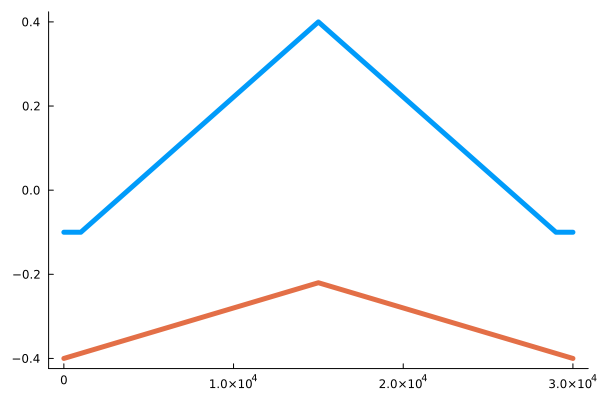

In [174]:
Plots.plot(tr,grid=false,legend=false, linewidth=5)
Plots.plot!(inh_input*-1,grid=false,legend=false, linewidth=5)
# Plots.plot!(inh_input*.04,grid=false,legend=false, linewidth=5)


## Run whole simulation to get new order

In [136]:
full_input = zeros((nr_s, sim_length))
@time spike_array, vs_array,pt_arr = run_sim();

301.578457 seconds (15.93 G allocations: 265.462 GiB, 17.28% gc time, 0.06% compilation time)


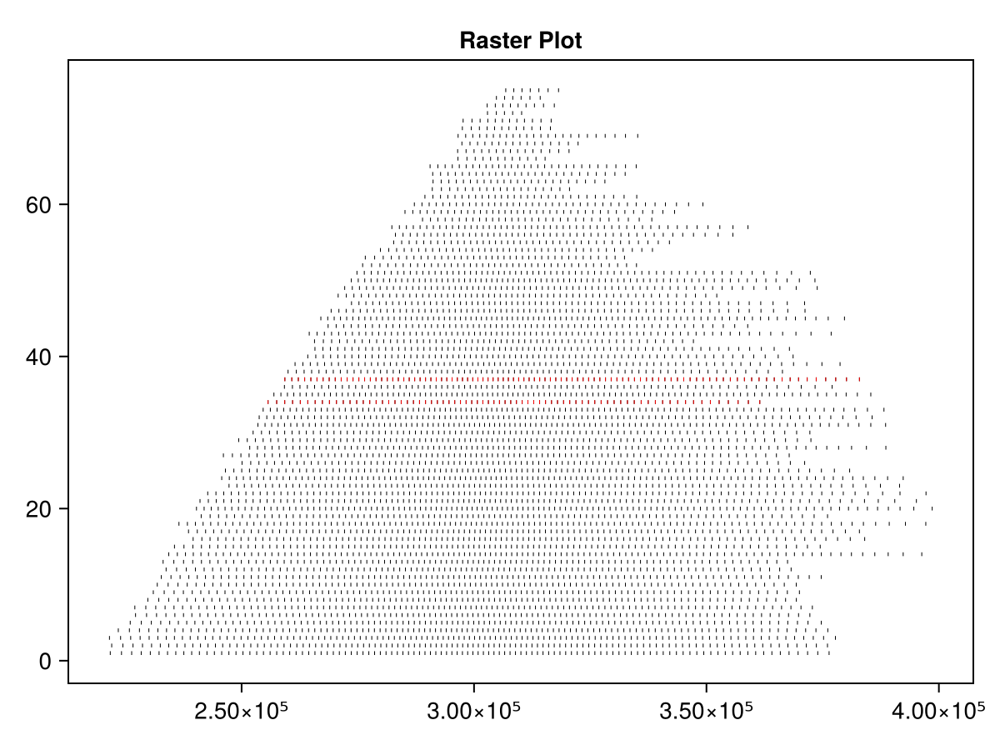

CairoMakie.Screen{IMAGE}


In [137]:
n_neurons, n_times = size(spike_array)
CairoMakie.activate!()

fig = CairoMakie.Figure()

ax = Axis(fig[1, 1], title="Raster Plot")
line_height = 0.5
line_thickness = 0.5

# Define a small horizontal offset between spikes
horizontal_offset = 100  # Adjust this value as needed to separate the spikes

for t in 1:n_times
    for neuron in 1:n_neurons
        if spike_array[neuron, t] == 1.0
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * (neuron - 1)  # Adjust the multiplier for spacing
            lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:black, linewidth=line_thickness)

            if neuron==34 || neuron==37
                lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:red, linewidth=line_thickness)
            end

        end
    end
end
ax.xgridvisible = false
ax.ygridvisible = false



# xlabel!(ax, "Time")
# ylabel!(ax, "Neuron")a
display(fig)


In [10]:
non_zero_row = findall(i -> any(x -> x != 0, spike_array[i, :]), 1:size(spike_array, 1))
pos_first_spike = zeros(length(non_zero_row))

for i in 1:length(non_zero_row)
    neuron_idx = non_zero_row[i] # Retrieve the original row index
    pos_first_spike[i] = findfirst(x -> x == 1, spike_array[neuron_idx, :]) # Find first spike
end

neuron_order = sortperm(pos_first_spike)# Sort the neurons by their recruitment

spike_array_ = spike_array[neuron_order, :];

n_neurons, n_times = size(spike_array_)
CairoMakie.activate!()

fig = CairoMakie.Figure()

ax = Axis(fig[1, 1], title="Raster Plot")
line_height = 0.5
line_thickness = 0.5

# Define a small horizontal offset between spikes
horizontal_offset = 100  # Adjust this value as needed to separate the spikes

for t in 1:n_times
    for neuron in 1:n_neurons
        if spike_array_[neuron, t] == 1.0
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * (neuron - 1)  # Adjust the multiplier for spacing
            lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:black, linewidth=line_thickness)
            if neuron==23 || neuron==21
                lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:red, linewidth=line_thickness)
            end
        end
    end
end
ax.xgridvisible = false
ax.ygridvisible = false



# xlabel!(ax, "Time")
# ylabel!(ax, "Neuron")a
display(fig)


In [21]:
neuron_order[23]

45

In [248]:
IF[34]

0.9174939259602283

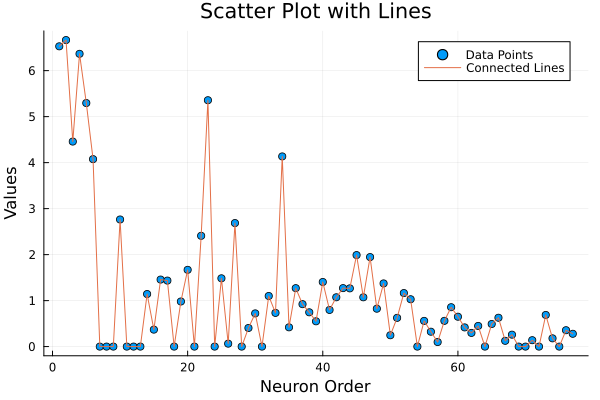

In [12]:
Plots.scatter(VthCa_newTA[1, neuron_order], label="Data Points", title="Scatter Plot with Lines", xlabel="Neuron Order", ylabel="Values")
Plots.plot!(VthCa_newTA[1, neuron_order], label="Connected Lines")

#### Checking pair of MNs

In [116]:
# mn1=86; mn2=31
# inh_input1 = vcat(fill(factor*amplitude, Int(sim_length/2)), range(factor* amplitude, stop=factor* amplitude+values_inh[mn1]*amplitude, length=Int(sim_length/2)))
# inh_input2 = vcat(fill(factor*amplitude, Int(sim_length/2)), range(factor* amplitude, stop=factor* amplitude+values_inh[mn2]*amplitude, length=Int(sim_length/2)))
# #
# Plots.plot(inh_input1,width=3)
# Plots.plot!(inh_input2,width=3)

In [24]:
mn1=34; mn2=37
spike_arr_mn1, _ = run_sim_onemn(MN_list[mn1], mn1,inh_input)  
spike_arr_mn2, _ = run_sim_onemn(MN_list[mn2], mn2,inh_input)

([0 0 … 0 0], [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])

In [25]:
## NATALIA OF THE FUTURE DONT RUN THIS CODE TWICE BECAUSE YOU ARE MAKING A TRAJECTORY WITH LESS POINTS IN EACH ITERATION

smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;

# Plots.plot(trajectory2_controlled[:,1],trajectory2_controlled[:,1])  # Controlled trajectory from neurons)


30000×2 Matrix{Float64}:
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 ⋮    
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0

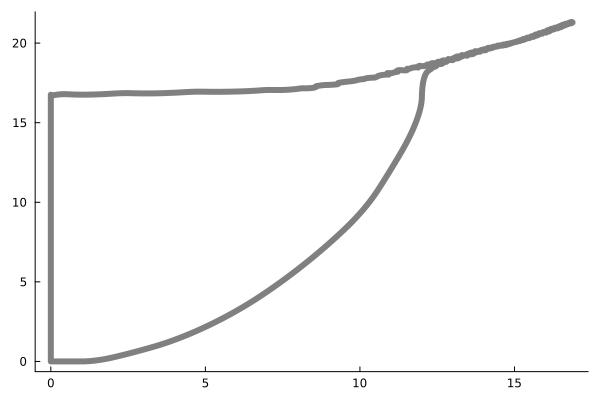

In [26]:
y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2]);
x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]));
trajectory1 = hcat(x_values, y_values) ; # This is the line that would make us achieve flexible control;

# Plots.plot(trajectory2_controlled[1:15000,1],trajectory2_controlled[1:15000,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory2_controlled[15000:30000,1],trajectory2_controlled[15000:30000,2])  # Controlled trajectory from neurons)
Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2],grid=false,legend=false,linewidth=6,color= :gray)  # Controlled trajectory from neurons)

# Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)


In [73]:
submatrix = trajectory2_controlled[15000:30000, :]

# Count how many rows have column 1 == 0 and column 2 ≠ 0
count(x -> x[1] == 0 && x[2] != 0, eachrow(submatrix))



67

In [74]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_3437_change_inh_with_startPIC/originaltrajectory_TA_MN34_37_inh_PICstart.jld2" trajectory2_controlled


## Control algorithm

In [178]:
###################### EXC ###################### (just controlling exc)
#################################################

# Control parameters
kp = Float32(4)  
kd = Float32(1)  
dt = Float32(0.1) 

# Motoneurons we are interested in comparing
mn1 = 34
mn2 = 37

# Init
previous_error= 0.0

tr_new = copy(tr)


for  iteration in 1:20

    commoninput = tr_new  

    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_onemn(MN_list[mn1], mn1, inh_input) 
    spike_arr_mn2, _ = run_sim_onemn(MN_list[mn2], mn2, inh_input)  

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg #avg every 20 points
    

    # Trajectory we want to achieve (for flexibility)
    y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2])
    x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    trajectory1 = hcat(x_values, y_values)  

    # x_values = zeros(length(trajectory2_controlled[:, 2]))
    # y_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]));
    # trajectory1 = hcat(x_values, y_values) ; # This is the line that would make us achieve flexible control;
    

    start= Int(size(trajectory1, 1)/2) #we just want the controller to start half way

    flag=0
    
   
    for i in start:size(trajectory1, 1) 

        # computation of the euclidean error
        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        euclidean_error = sqrt(error1^2 + error2^2)

        # ERRORS FROM CONTROL OUTPUT
        # integral_error += euclidean_error * dt  
        derivative_error = (euclidean_error - previous_error) / dt
        control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 

        control_output *= 0.0001 #adaptative

        tr_new[i] += control_output  

        

        if tr_new[i]  >= 0.4 #it cant be greater than this 
            tr_new[i]=0.4
        end

        tr_new[15000]=amplitude


        if round(trajectory2_controlled[i, 1])==0
            tr_new[i] += control_output/0.7
        end

        previous_error = euclidean_error


    end

    
end

In [479]:
###################### EXC ###################### (just controlling exc)
#################################################

# Control parameters
kp = Float32(4)  
kd = Float32(1)  
dt = Float32(0.1) 

# Motoneurons we are interested in comparing
mn1 = 34
mn2 = 37

# Init
previous_error= 0.0
tr_new = copy(tr)

m1_inactive= false

for iteration in 1:20

    commoninput = tr_new  

    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_onemn(MN_list[mn1], mn1, inh_input) 
    spike_arr_mn2, _ = run_sim_onemn(MN_list[mn2], mn2, inh_input)  

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg #avg every 20 points

    # Trajectory we want to achieve (for flexibility)
    start_x = 5; end_x = maximum(trajectory2_controlled[:, 1])
    start_y = 10; end_y = maximum(trajectory2_controlled[:, 2])
    x_values_diag = range(start_x, stop=Int(round(end_x)), length=Int(length(trajectory2_controlled[:, 1])/2))
    y_values_diag = range(start_y, stop=Int(round(end_y)), length=Int(length(trajectory2_controlled[:, 1])/2))
    trajectory1_diagonal = hcat(x_values_diag, y_values_diag)
    
    # x_values_vert = zeros(15000) 
    # y_values_vert = range(10, stop=maximum(trajectory2_controlled[:, 2]), length=15000)  
    # trajectory1_vertical = hcat(x_values_vert, y_values_vert)
    y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2])
    x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    trajectory1_vertical = hcat(x_values, y_values)  


    start= Int(size(trajectory1_vertical, 1)/2) #we just want the controller to start half way
       
    for i in start:(length(trajectory2_controlled[:, 1]))

        if round(trajectory2_controlled[i, 1])>5

            if i==start
                error1 = trajectory1_diagonal[i, 1] - trajectory2_controlled[i, 1]
                error2 = trajectory1_diagonal[i, 2] - trajectory2_controlled[i, 2]
                euclidean_error = sqrt(error1^2 + error2^2)

            else
                error1 = trajectory1_diagonal[start-(i-start)+1, 1] - trajectory2_controlled[i, 1]
                error2 = trajectory1_diagonal[start-(i-start), 2] - trajectory2_controlled[i, 2]
                euclidean_error = sqrt(error1^2 + error2^2)

            end

            derivative_error = (euclidean_error - previous_error) / dt
            control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 
            control_output *= 0.001 #adaptative

            tr_new[i] -= control_output  

        

            if tr_new[i]  <0 #it cant be smaller than this 
                tr_new[i]=0
            end

            tr_new[15000]=amplitude


        else

            # computation of the euclidean error
            error1 = trajectory1_vertical[i, 1] - trajectory2_controlled[i, 1]
            error2 = trajectory1_vertical[i, 2] - trajectory2_controlled[i, 2]
            euclidean_error = sqrt(error1^2 + error2^2)

            # ERRORS FROM CONTROL OUTPUT
            derivative_error = (euclidean_error - previous_error) / dt
            control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 

            control_output *= 0.000008 #adaptative

            tr_new[i] += control_output

            # if tr_new[i]  <0.25#it cant be greater than this 
            #     tr_new[i]=0.25
            # end
            


        end

        if iteration>18 && i>20000
            error1 = trajectory1_vertical[i, 1] - trajectory2_controlled[i, 1]
            error2 = trajectory1_vertical[i, 2] - trajectory2_controlled[i, 2]
            euclidean_error = sqrt(error1^2 + error2^2)

            # ERRORS FROM CONTROL OUTPUT
            derivative_error = (euclidean_error - previous_error) / dt
            control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 

            control_output *= 0.001 #adaptative

            tr_new[i] += control_output


        end

        previous_error = euclidean_error


    end


    
end

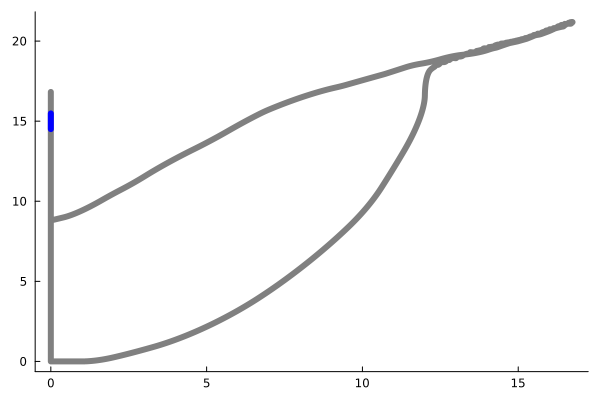

In [477]:
Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2],grid=false,legend=false,linewidth=6,color= :gray)  # Controlled trajectory from neurons)
Plots.plot!(trajectory2_controlled[21000:22000,1],trajectory2_controlled[21000:22000,2],grid=false,legend=false,linewidth=6,color= :blue)  # Controlled trajectory from neurons)

# Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)

In [318]:
size(trajectory1, 1)

30000

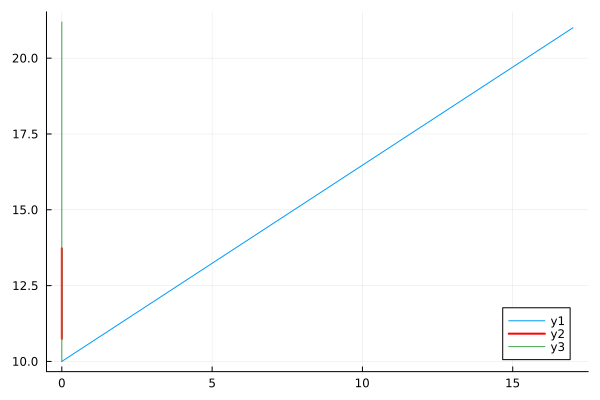

In [287]:
start_x = 0; end_x = maximum(trajectory2_controlled[:, 1])
start_y = 10; end_y = maximum(trajectory2_controlled[:, 2])
x_values_diag = range(start_x, stop=Int(round(end_x)), length=15000)
y_values_diag = range(start_y, stop=Int(round(end_y)), length=15000)
trajectory1_diagonal = hcat(x_values_diag, y_values_diag)

x_values_vert = zeros(15000) 
y_values_vert = range(10, stop=maximum(trajectory2_controlled[:, 2]), length=15000)  
trajectory1_vertical = hcat(x_values_vert, y_values_vert)

Plots.plot(trajectory1_diagonal[1:15000,1],trajectory1_diagonal[1:15000,2])
Plots.plot!(trajectory1_vertical[1000:5000,1],trajectory1_vertical[1000:5000,2], color=:red,width=2)
# Plots.plot!(trajectory2_controlled[:,1],trajectory2_controlled[:,2])
Plots.plot!(trajectory1_vertical[:,1],trajectory1_vertical[:,2])

In [171]:
trajectory1_diagonal[1495,1]

1.693312887525835

In [152]:
prutrajectory1_diagonal

0.0:0.0007118622979738786:21.355157076918385

In [ ]:
# JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/new_exc_flexibility_ONLYEXCchange_5Aug.jld2" tr_new
# 

In [228]:
submatrix = trajectory2_controlled[25000:30000, :]

# Count how many rows have column 1 == 0 and column 2 ≠ 0
count(x -> x[1] == 0 && x[2] != 0, eachrow(submatrix))


# # Initialize a counter for valid points
# counter = 0

# # Iterate through each pair of consecutive rows and check the conditions
# for i in 1:size(submatrix, 1)-1
#     if submatrix[i, 1] == 0 && submatrix[i, 2] != 0 && submatrix[i, 2] < submatrix[i+1, 2]
#         counter += 1
#     end
# end

# # Display the counter
# counter

4960

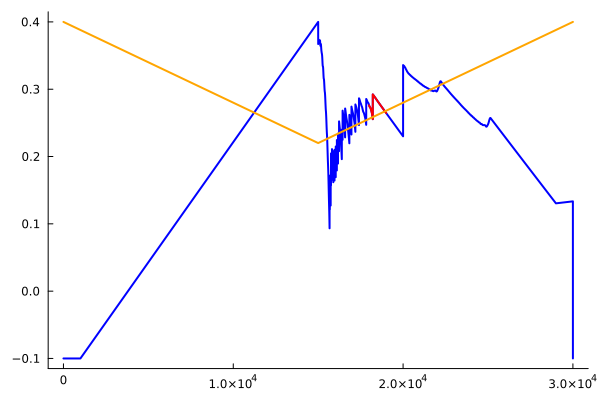

In [478]:
Plots.plot([1:30000],tr_new,grid=false,legend=false,linewidth=2,color= :blue)  # Controlled trajectory from neurons)
Plots.plot!([18000:19000],tr_new[18000:19000],grid=false,legend=false,linewidth=2,color= :red)  # Controlled trajectory from neurons)

Plots.plot!([1:30000],inh_input,grid=false,legend=false,linewidth=2,color= :orange)  # Controlled trajectory from neurons)


In [ ]:
Plots.scatter([2,6],[-59,23],grid=false, xlim=(=0.1,8))

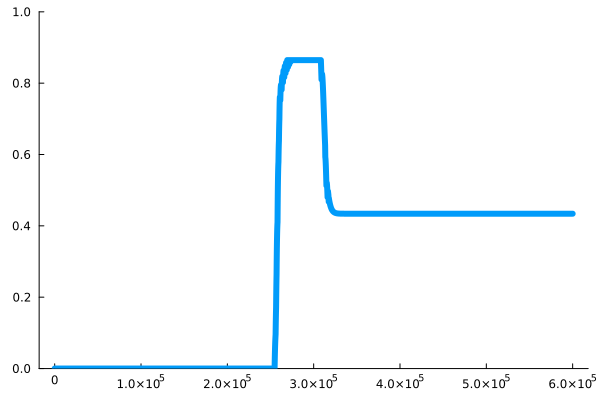

In [412]:
spike_array= vcat(spike_arr_mn1,spike_arr_mn2)
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);

Apeak_S= [Apeak_S[mn1], Apeak_S[mn2]]
tpeak_S= [tpeak_S[mn1], tpeak_S[mn2]]
tetanic_S= [tetanic_S[mn1], tetanic_S[mn2]]

T=0.05
twforce = zeros(size(spike_array))

for i in 1:size(spike_array, 1)
    firings = copy(spike_array) /0.05


    # filter coefficients
    a = [1, -2 * exp(-T / tpeak_S[i]), exp(-2 * T / tpeak_S[i])]
    b = [0, Apeak_S[i] * (T^2 / tpeak_S[i]) * exp(1 - T / tpeak_S[i])]

    twforce[i, :] = filt(b, a, firings[i, :])

    # Tetanic Limit
    twforce[i, twforce[i, :] .> tetanic_S[i]] .= tetanic_S[i]
end

force = sum(twforce, dims=1)# Sum forces from both neurons


Plots.plot([1:600000],force[1,:],ylim=[0,1],lw=6,grid=false,legend=false)


In [428]:
force_derivative[500000:599999]

599900-element Vector{Float64}:
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

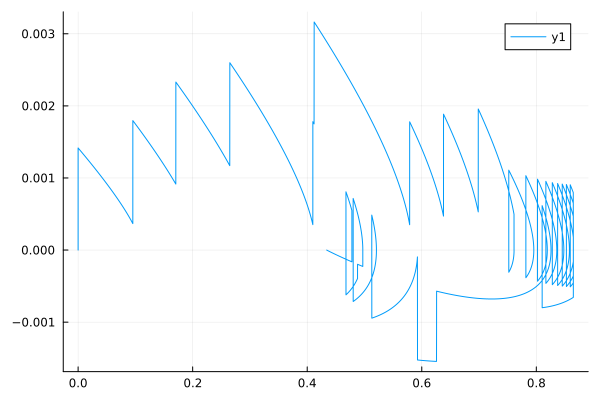

In [430]:
dt = 0.1  

force_derivative = diff(force[1,:])./ dt

Plots.plot(force[1,:][1:599999], force_derivative[1:599999])

In [86]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_3437_change_inh_with_startPIC/exc_TA_MN34_37_inh_PICstart.jld2" tr_new
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_3437_change_inh_with_startPIC/trajectory_controlled_TA_MN34_37_inh_PICstart.jld2" trajectory2_controlled
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_3437_change_inh_with_startPIC/inh_TA_MN34_37_inh_PICstart.jld2" inh_input
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_3437_change_inh_with_startPIC/force_TA_MN34_37_inh_PICstart.jld2" force


